In [165]:
from src.slm_initialise import slm_initialise
from src.utils import *
from src.plots import plot_fit,bb
from slmsuite.holography.algorithms import FeedbackHologram
from slmsuite.holography.toolbox import convert_vector
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [10]:
fs = slm_initialise(force=True,verbose=True)

Display Positions:
#,  Position
0,  x=1920, y=0, width=1280, height=1024
1,  x=0, y=0, width=1920, height=1200 (main)
Initializing pyglet... success
Searching for window with display_number=0... success
Creating window... [Errno 2] No such file or directory: 'C:\\Users\\QC\\Envs\\SLM_new\\Lib\\site-packages\\slmsuite\\hardware\\..\\..\\docs\\source\\static\\slmsuite-notext-16x16.png'
success
ThorCam serials:
'12975'
Looking for cameras... success
ThorCam sn '12975' initializing... success


array([[1, 2, 3, ..., 2, 1, 3],
       [1, 2, 1, ..., 2, 1, 1],
       [2, 2, 2, ..., 1, 2, 1],
       ...,
       [2, 3, 2, ..., 3, 3, 2],
       [2, 2, 1, ..., 3, 2, 2],
       [3, 2, 2, ..., 2, 3, 2]], dtype=uint16)

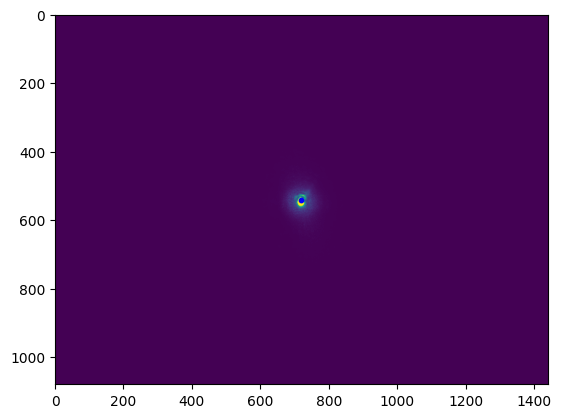

In [19]:
plot_cam(fs,phase="zero",centre=True, save=True)

In [20]:
calibrate(fs,vendor = True,refresh = False)

smooth:   0%|          | 0/16 [00:00<?, ?it/s]

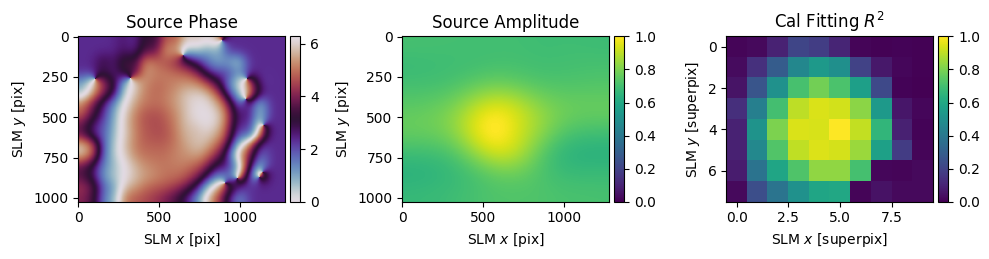

In [21]:
sp_calibrate(fs,refresh=False)

In [93]:
centrex = 1180
centrey = 230
n_spots = 5
r = 50
n = 2
rad = 150

bb_locations = np.array([[centrex+(i-2)*rad ,centrey + (j)*rad] for i in range(n) for j in range(n)]).T
spot_locations = np.array([[bb_locations[0][i - (i//n)%2] + r*np.cos(j*2*np.pi/5 - np.pi/2),bb_locations[1][i- (i//n)%2] + r*np.sin(j*2*np.pi/5 - np.pi/2)] for i in range(1,len(bb_locations.T),2) for j in range(5)]).T

n = 4
rad = 100
bb_locations = np.array([[centrex+(i-2)*rad ,centrey + (j-1)*rad] for i in range(n) for j in range(n)]).T
spot_locations = np.array([[centrex+(i-2)*rad + 50,centrey + (j-1)*rad + 50] for i in range(n) for j in range(n)]).T


In [94]:
bb_locations

array([[ 980,  980,  980,  980, 1080, 1080, 1080, 1080, 1180, 1180, 1180,
        1180, 1280, 1280, 1280, 1280],
       [ 130,  230,  330,  430,  130,  230,  330,  430,  130,  230,  330,
         430,  130,  230,  330,  430]])

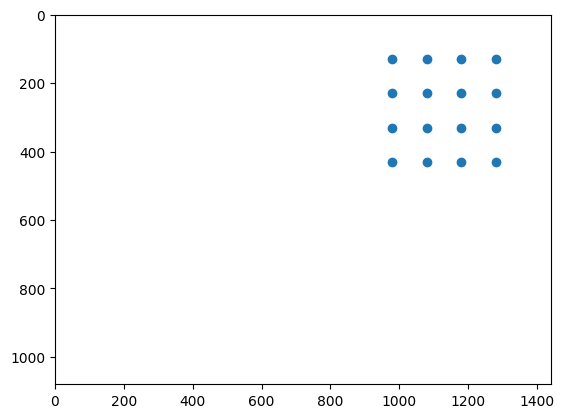

c:\Users\QC\envs\SLM_new\Lib\site-packages\slmsuite\holography\algorithms\_hologram.py:377: UserWarning: Hologram target shape (1024, 1280) is not a power of 2; consider using .get_padded_shape() to pad to powers of 2 and speed up FFT computation. While some FFT solvers support other prime powers (3, 5, 7, ...), literature suggests that GPU support is best for powers of 2.
  warnings.warn(


  0%|          | 0/30 [00:00<?, ?it/s]

testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing sh

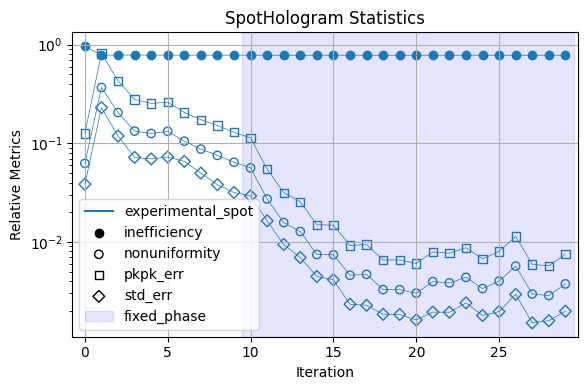

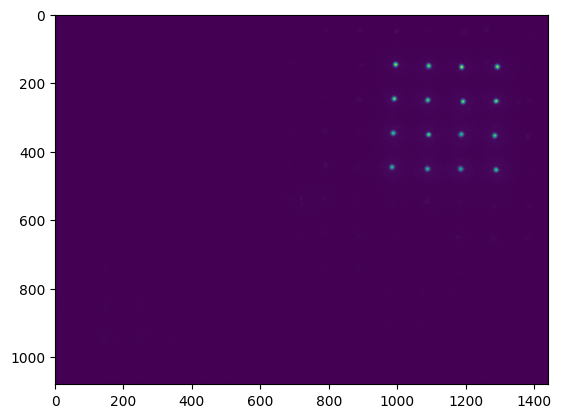

In [99]:
holo = create_tweezers(fs,bb_locations,30)

array([[1, 3, 1, ..., 2, 2, 1],
       [3, 2, 1, ..., 3, 2, 2],
       [2, 3, 2, ..., 3, 1, 1],
       ...,
       [3, 2, 3, ..., 2, 2, 2],
       [2, 3, 2, ..., 2, 2, 3],
       [3, 3, 3, ..., 2, 1, 2]], dtype=uint16)

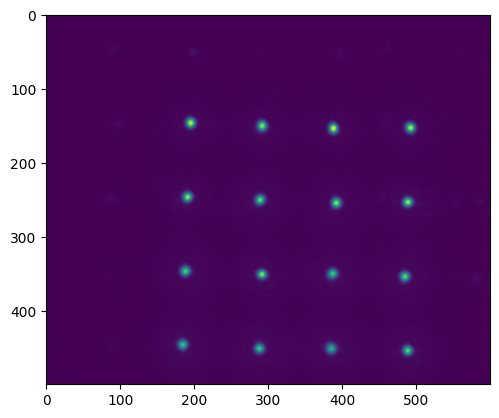

In [100]:
plot_cam(fs,limits=(slice(0, 500), slice(800, 1400)))

writing phase


array([[2, 3, 2, ..., 1, 3, 2],
       [2, 2, 2, ..., 2, 1, 1],
       [2, 2, 1, ..., 2, 1, 2],
       ...,
       [3, 2, 3, ..., 2, 2, 2],
       [3, 3, 3, ..., 3, 2, 3],
       [1, 3, 3, ..., 2, 3, 2]], dtype=uint16)

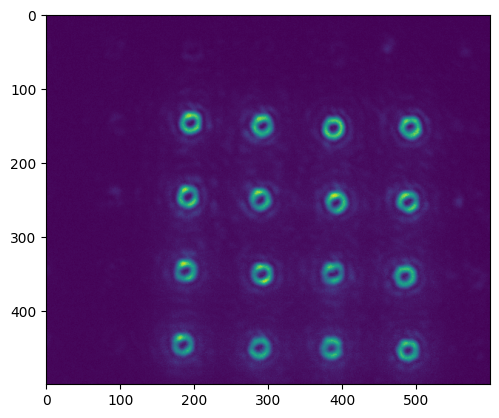

In [105]:
plot_cam(fs,phase = bottle_beam_phase(fs)+holo.phase,limits=(slice(0, 500), slice(800, 1400)))

writing phase


c:\Users\QC\envs\SLM_new\Lib\site-packages\slmsuite\hardware\slms\slm.py:357: UserWarning: The backwards-compatible alias SLM.write will be depreciated in favor of SLM.set_phase in a future release.
  warnings.warn(


array([[3, 2, 2, ..., 2, 2, 3],
       [1, 3, 2, ..., 2, 1, 2],
       [1, 1, 2, ..., 2, 2, 2],
       ...,
       [2, 3, 3, ..., 4, 3, 3],
       [3, 2, 3, ..., 4, 4, 3],
       [2, 4, 3, ..., 4, 3, 3]], dtype=uint16)

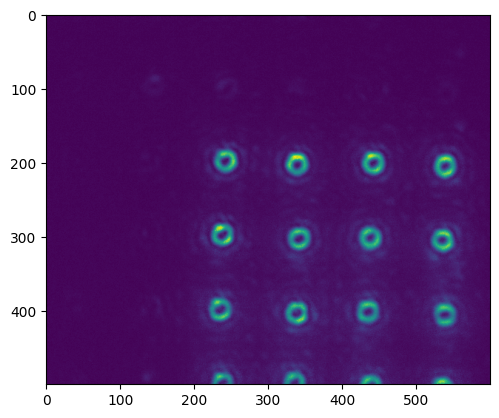

In [97]:
plot_cam(fs,phase = bottle_beam_phase(fs)+holo.phase,limits=(slice(0, 500), slice(800, 1400)))

writing phase


c:\Users\QC\envs\SLM_new\Lib\site-packages\slmsuite\hardware\slms\slm.py:357: UserWarning: The backwards-compatible alias SLM.write will be depreciated in favor of SLM.set_phase in a future release.
  warnings.warn(


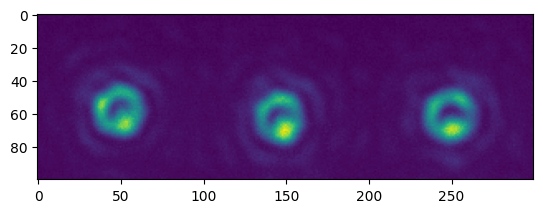

In [15]:
img = plot_cam(fs,phase = bottle_beam_phase(fs)+holo.phase,limits=(slice(50, 150), slice(950, 1250)))

## Combining g and bb

In [101]:
bb_phase = holo.phase

In [98]:
spot_phase = holo.phase

In [116]:
p = random_masking(spot_phase,bb_phase+bottle_beam_phase(fs))

writing phase


array([[2, 2, 3, ..., 2, 2, 2],
       [2, 2, 2, ..., 2, 3, 3],
       [4, 3, 3, ..., 2, 3, 2],
       ...,
       [3, 3, 2, ..., 3, 2, 2],
       [2, 3, 3, ..., 3, 2, 2],
       [3, 3, 3, ..., 3, 4, 2]], dtype=uint16)

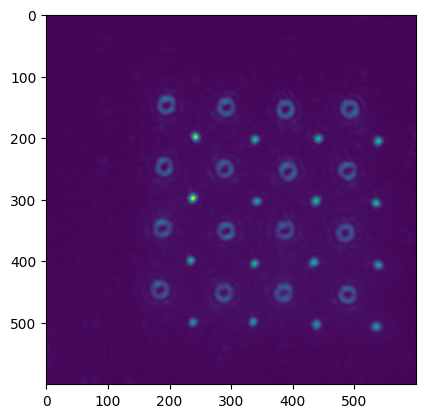

In [117]:
plot_cam(fs,phase = p ,limits=(slice(0, 600), slice(800, 1400)))

In [211]:
save_cam(fs,phase = p,file_name = "bb_g")

writing phase


c:\Users\QC\envs\SLM_new\Lib\site-packages\slmsuite\hardware\slms\slm.py:357: UserWarning: The backwards-compatible alias SLM.write will be depreciated in favor of SLM.set_phase in a future release.
  warnings.warn(


In [222]:
save_cam(fs,phase = spot_phase,file_name = "g")

writing phase


c:\Users\QC\envs\SLM_new\Lib\site-packages\slmsuite\hardware\slms\slm.py:357: UserWarning: The backwards-compatible alias SLM.write will be depreciated in favor of SLM.set_phase in a future release.
  warnings.warn(


In [223]:
save_cam(fs,phase = bb_phase+bottle_beam_phase(fs),file_name = "bb")

writing phase


array([[2, 2, 2, ..., 2, 2, 2],
       [2, 2, 2, ..., 2, 1, 1],
       [2, 2, 2, ..., 2, 2, 2],
       ...,
       [1, 3, 2, ..., 1, 2, 2],
       [3, 3, 3, ..., 3, 2, 2],
       [2, 2, 2, ..., 2, 2, 3]], dtype=uint16)

## Bottle beam axial imaging

In [127]:
lens_phase(fs,0)

array([0., 0., 0., ..., 0., 0., 0.])

In [175]:
imgs = get_3d_images(fs,p,N = 100)

writing phase


c:\Users\QC\envs\SLM_new\Lib\site-packages\slmsuite\hardware\slms\slm.py:357: UserWarning: The backwards-compatible alias SLM.write will be depreciated in favor of SLM.set_phase in a future release.
  warnings.warn(


writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writin

(100, 1080)


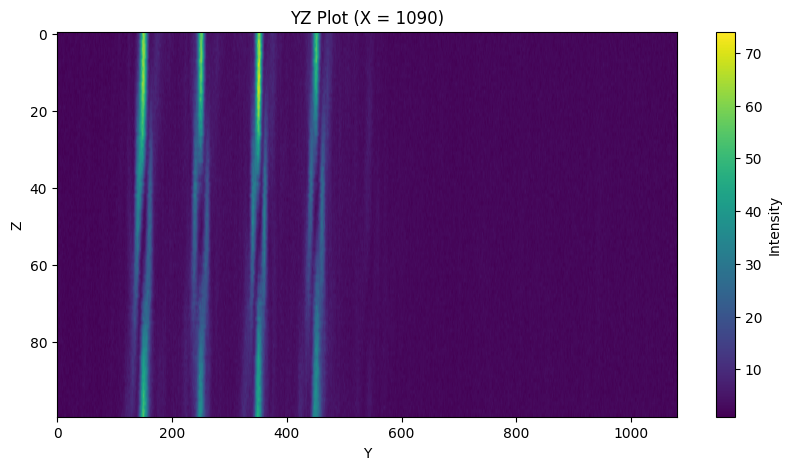

In [207]:
plot_axial(plane='YZ',index = 1090,images = imgs)

(100, 1440)


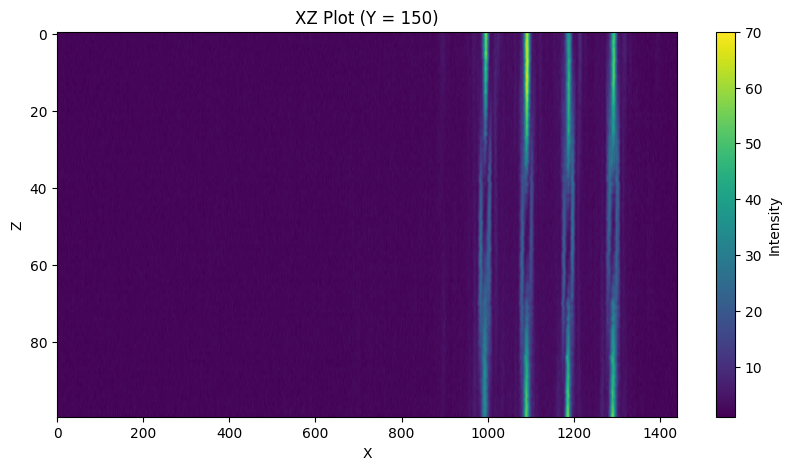

In [195]:
plot_axial(plane='XZ',index = 150,images = imgs)

(100, 1080)


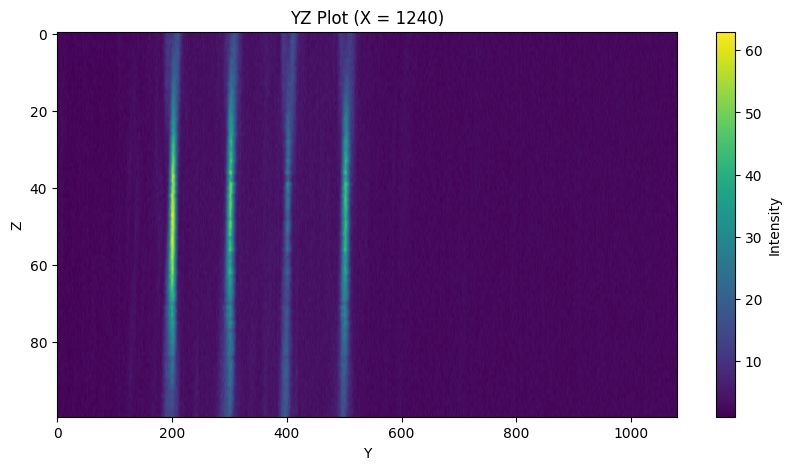

In [210]:
plot_axial(plane='YZ',index = 1240,images = imgs)

(100, 1440)


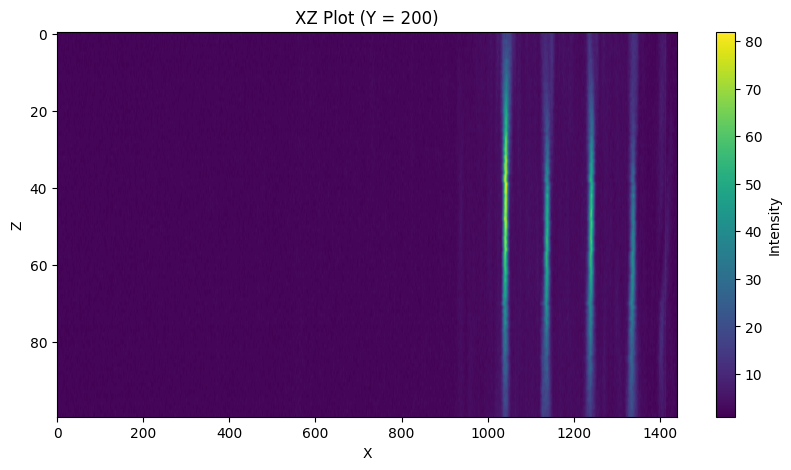

In [209]:
plot_axial(plane='XZ',index = 200,images = imgs)

writing phase


c:\Users\QC\envs\SLM_new\Lib\site-packages\slmsuite\hardware\slms\slm.py:357: UserWarning: The backwards-compatible alias SLM.write will be depreciated in favor of SLM.set_phase in a future release.
  warnings.warn(


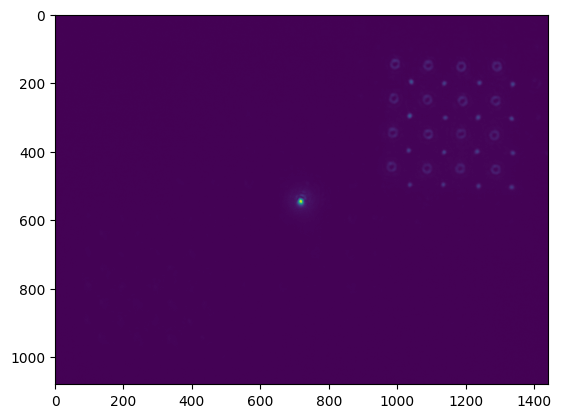

In [227]:
img = plot_cam(fs,phase = p)

In [ ]:
plot_axial(plane='XZ',index = 150,images = imgs)

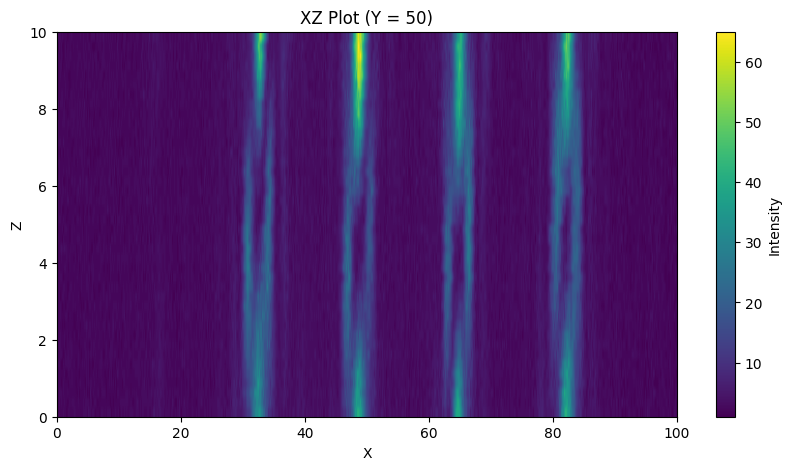

In [163]:


# Example: Plot XZ plot for a fixed Y (e.g., Y = 50)
y_index = 150
xz_data = image_stack[:, y_index, :]  # Slice along Y to get XZ plane

# Plot XZ
plt.figure(figsize=(10, 5))
plt.imshow(xz_data, aspect='auto', cmap='viridis', extent=[0, 100, 0, 10])
plt.colorbar(label="Intensity")
plt.xlabel("X")
plt.ylabel("Z")
plt.title("XZ Plot (Y = 50)")
plt.show()

In [120]:
fs.slm.shape

(1024, 1280)

In [244]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from tifffile import imread
import os
# === Define models ===
def single_gaussian(x, A, x0, sigma, offset):
    return A * np.exp(-(x - x0)**2 / (2 * sigma**2)) + offset
def dark_trap_model(x, A1, sigma1, A2, sigma2, x0, offset):
    return (A1 * np.exp(-(x - x0)**2 / (2 * sigma1**2))
           - A2 * np.exp(-(x - x0)**2 / (2 * sigma2**2))
           + offset)
# === Analyze trap ===
def analyze_trap(img, trap_type='bright', direction='horizontal'):
    center_y, center_x = np.array(img.shape) // 2
    if direction == 'horizontal':
        x_vals = np.arange(img.shape[1])
        line_data = img[center_y, :]
    elif direction == 'vertical':
        x_vals = np.arange(img.shape[0])
        line_data = img[:, center_x]
    else:
        raise ValueError("direction must be 'horizontal' or 'vertical'")
    # Fit appropriate model
    if trap_type == 'bright':
        model = single_gaussian
        p0 = [line_data.max() - line_data.min(), x_vals[len(x_vals)//2], 10, line_data.min()]
    elif trap_type == 'dark':
        model = dark_trap_model
        A1_guess = line_data.max() - line_data.min()
        A2_guess = A1_guess / 2
        sigma1_guess = 15
        sigma2_guess = 5
        x0_guess = x_vals[len(x_vals)//2]
        offset_guess = line_data.min()
        p0 = [A1_guess, sigma1_guess, A2_guess, sigma2_guess, x0_guess, offset_guess]
    else:
        raise ValueError("trap_type must be 'bright' or 'dark'")
    popt, pcov = curve_fit(model, x_vals, line_data, p0=p0,maxfev = 10000)
    fit_data = model(x_vals, *popt)
    # Plot
    plt.figure(figsize=(8, 4))
    plt.plot(x_vals, line_data, label='Line scan data')
    plt.plot(x_vals, fit_data, 'r--', label='Fit')
    plt.title(f'{trap_type.capitalize()}')
    plt.xlabel('Pixel position')
    plt.ylabel('Intensity')
    plt.legend()
    plt.tight_layout()
    plt.show()
    return popt
# === Example usage ===
# analyze_trap('bright_trap.tif', trap_type='bright', direction='horizontal')
# analyze_trap('dark_trap.tif', trap_type='dark', direction='horizontal')

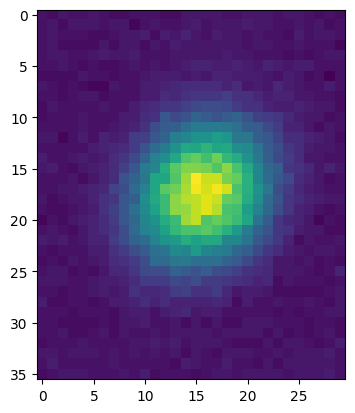

In [258]:
plt.imshow(img[284:320,1220:1250])

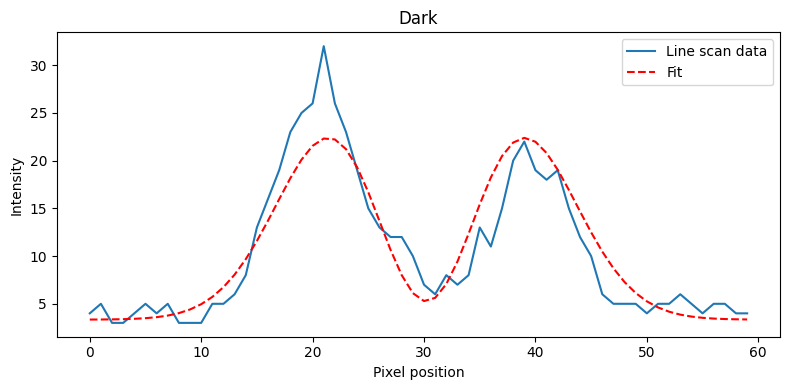

array([8.75936759e+03, 6.36562876e+00, 8.75744993e+03, 6.34754639e+00,
       3.02163803e+01, 3.34144558e+00])

In [246]:
analyze_trap(img[220:280,1160:1220], trap_type='dark', direction='horizontal')

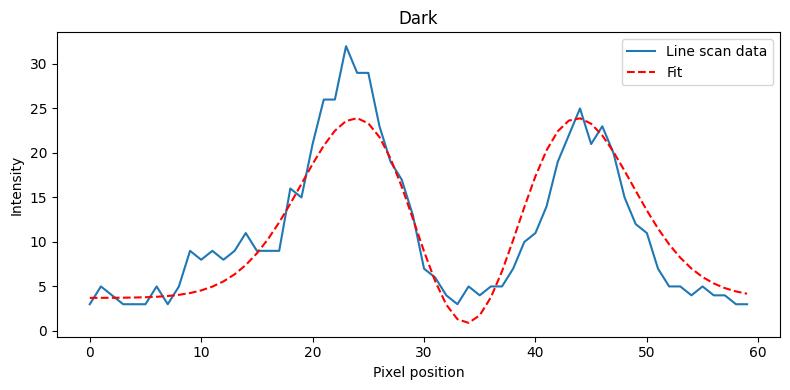

array([1.05084461e+04, 6.88050917e+00, 1.05112723e+04, 6.86165285e+00,
       3.38251662e+01, 3.71050420e+00])

In [247]:
analyze_trap(img[220:280,1160:1220], trap_type='dark', direction='vertical')

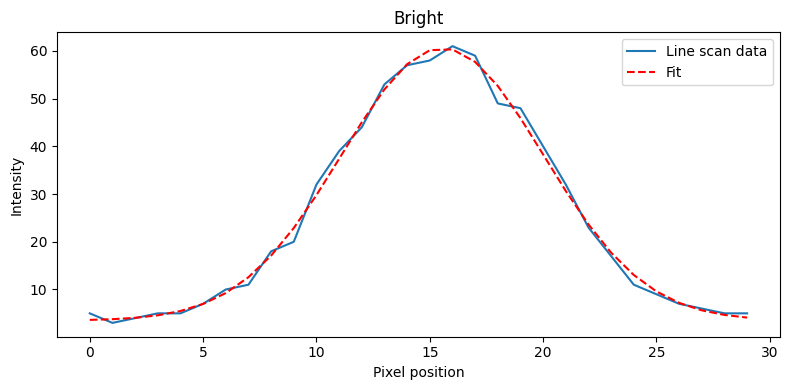

array([57.10641317, 15.55880209,  4.46223059,  3.49706461])

In [259]:
analyze_trap(img[284:320,1220:1250], trap_type='bright', direction='horizontal')

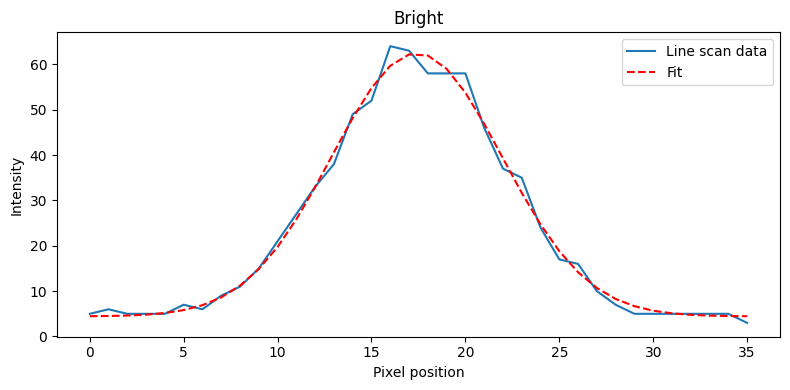

array([57.98601199, 17.41350018,  4.54305241,  4.43660419])

In [260]:
analyze_trap(img[284:320,1220:1250], trap_type='bright', direction='vertical')

optimised params are [  2.04877505   2.24436189  10.7578366    9.88192125 548.52287754
  52.31954357   2.2751408 ]


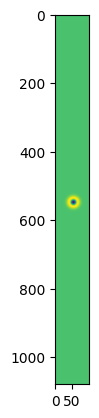

In [261]:
plot_fit(target = img[:,0:100],trap = "bb")

writing phase


c:\Users\QC\envs\SLM_new\Lib\site-packages\slmsuite\hardware\slms\slm.py:357: UserWarning:

The backwards-compatible alias SLM.write will be depreciated in favor of SLM.set_phase in a future release.



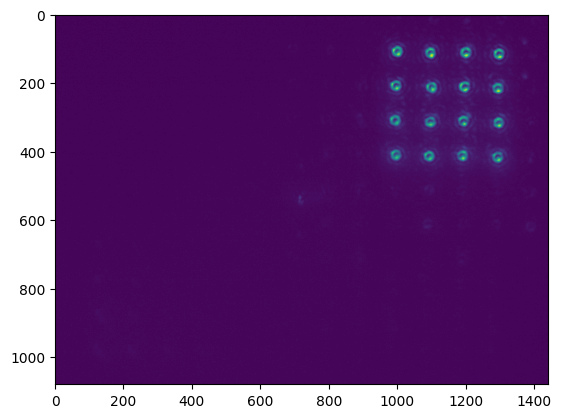

In [21]:
img = plot_cam(fs,phase = bottle_beam_phase(fs)+holo.phase)

In [120]:
convert_vector((0,0),hardware=fs,from_units="ij",to_units="knm")

array([[734.6943901 ],
       [406.69347811]])

In [127]:
(*convert_vector((600,600),hardware=fs,from_units="knm",to_units="ij"))

SyntaxError: cannot use starred expression here (545687825.py, line 1)

In [ ]:
fs.ijcam_to_knmslm((0,0))

AttributeError: 'FourierSLM' object has no attribute 'ijcam_to_knmslm'

In [9]:
scaling = 1
target = np.array([[bb(x,y,2.65128552e+04, 2.65128552e+04, 9.26105422*scaling, 9.23567108*scaling,1180,230) for x in range(fs.cam.shape[1]*scaling)] for y in range(fs.cam.shape[0]*scaling)])

In [29]:
hologram = FeedbackHologram(shape = (2048*2,2048*2),target_ij=target, cameraslm=fs)

In [11]:
fs.slm.shape

(1024, 1280)

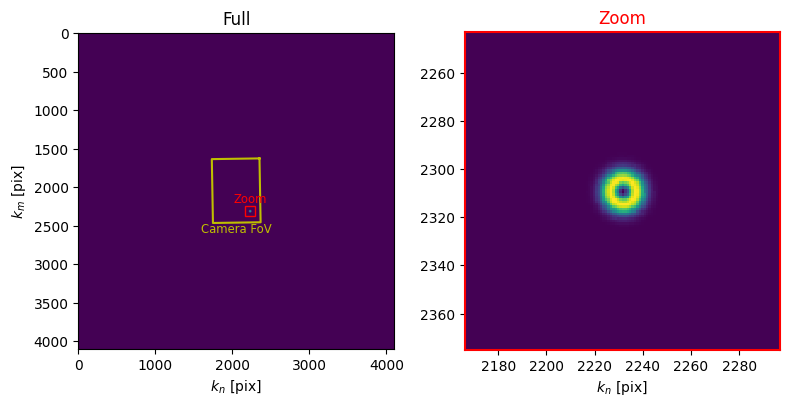

In [30]:
limits = hologram.plot_farfield(hologram.target)

In [31]:
hologram.optimize(
    method="WGS-Leonardo",
    maxiter=30,
    feedback='computational',
    stat_groups=['computational'],
    plot=True
)

  0%|          | 0/30 [00:00<?, ?it/s]

c:\Users\QC\envs\SLM_new\Lib\site-packages\slmsuite\holography\algorithms\_hologram.py:1794: RuntimeWarning: divide by zero encountered in divide
  xp.divide(feedback_corrected, xp.array(target_amp, copy=(False if np.__version__[0] == '1' else None)), out=feedback_corrected)
c:\Users\QC\envs\SLM_new\Lib\site-packages\slmsuite\holography\algorithms\_hologram.py:1794: RuntimeWarning: overflow encountered in divide
  xp.divide(feedback_corrected, xp.array(target_amp, copy=(False if np.__version__[0] == '1' else None)), out=feedback_corrected)


<Axes: title={'center': 'FeedbackHologram Statistics'}, xlabel='Iteration', ylabel='Relative Metrics'>

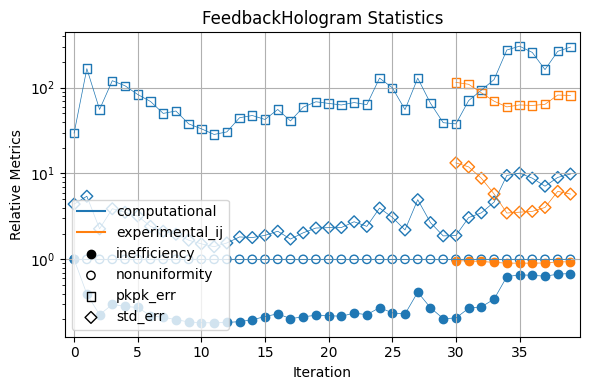

In [35]:
hologram.plot_stats()

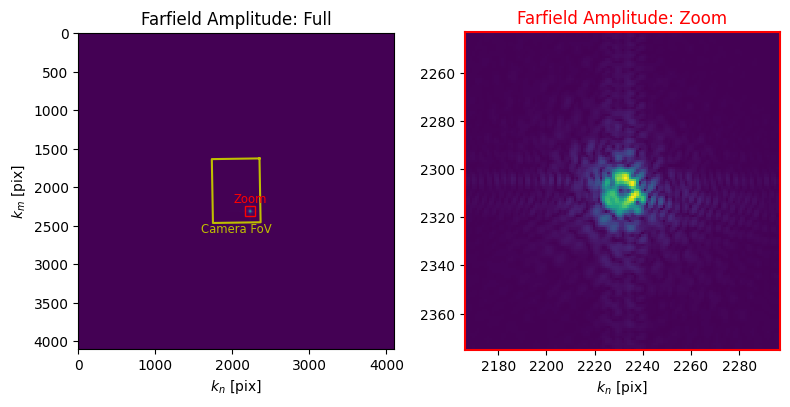

[array([2166, 2297]), array([2243, 2375])]

In [33]:
hologram.plot_farfield()

In [37]:
hologram.optimize(
    method="WGS-Leonardo",
    maxiter=30,
    feedback='experimental',
    stat_groups=['computational', 'experimental'],
    blur_ij=1
)

  0%|          | 0/30 [00:00<?, ?it/s]

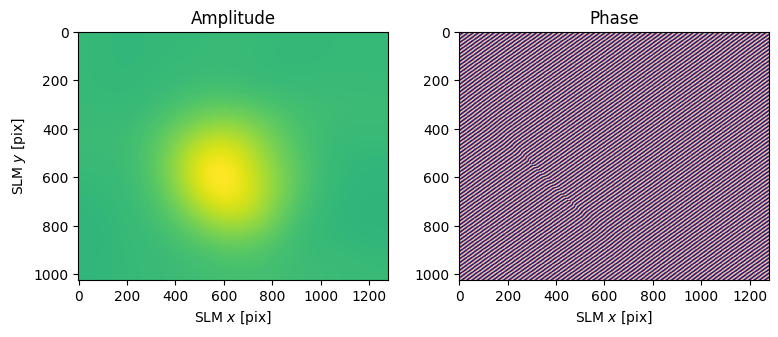

In [17]:
hologram.plot_nearfield()

In [38]:
hologram.get_phase()

array([[1.8198619, 2.1086264, 2.3973887, ..., 1.860147 , 2.149421 ,
        2.438695 ],
       [2.2212734, 2.5100446, 2.7988133, ..., 2.2548316, 2.5441108,
        2.8333898],
       [2.6226697, 2.9114473, 3.2002225, ..., 2.6495075, 2.938792 ,
        3.2280762],
       ...,
       [3.8582075, 4.1478634, 4.437515 , ..., 4.455541 , 4.7438745,
        5.032208 ],
       [4.255105 , 4.5447674, 4.8344254, ..., 4.859946 , 5.148267 ,
        5.4365883],
       [4.6519976, 4.9416666, 5.231331 , ..., 5.264428 , 5.5527363,
        5.8410463]], dtype=float32)

writing phase


array([[2, 2, 2, ..., 2, 1, 2],
       [2, 3, 1, ..., 2, 2, 1],
       [2, 2, 1, ..., 1, 1, 1],
       ...,
       [1, 3, 2, ..., 1, 3, 3],
       [2, 2, 2, ..., 2, 3, 2],
       [3, 2, 3, ..., 2, 3, 1]], dtype=uint16)

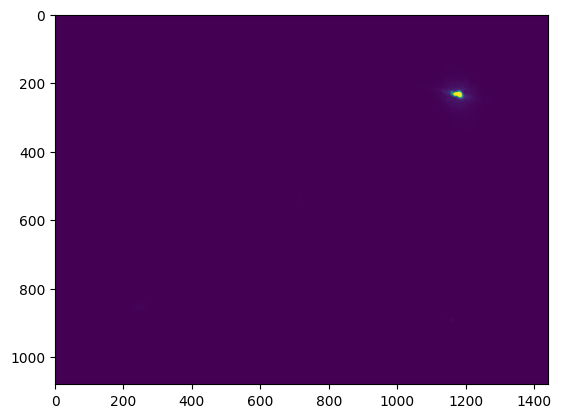

In [41]:
plot_cam(fs,phase=hologram.get_phase())

In [45]:
limits

[array([761, 808]), array([592, 627])]

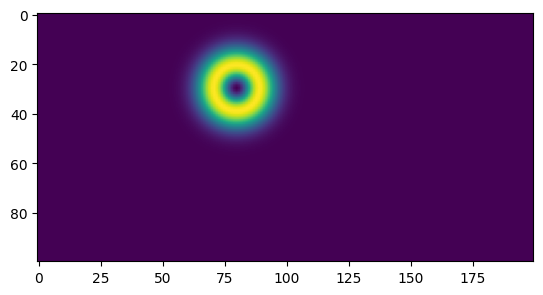

In [52]:
plt.imshow(target[200:300,1100:1300])